<a href="https://colab.research.google.com/github/varsityboi/speech-emotion-recognition/blob/main/notebooks/06_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06. Final evaluation of all models

This notebook loads every saved model and scores it on the validation set, the CREMA-D test set (13 unseen speakers) and RAVDESS. It reports accuracy, UAR and macro-F1, then compares the models with each other and with human listeners, per emotion, per gender and per speaker. The numbers printed here are the official results of the project.

**Inputs** (Google Drive `MyDrive/SER_Project`):
- `logmel_index.csv`: labels, split, speaker details and listener votes
- `logmel_X.npy`, `norm_stats.npz`, `logmel_X_noscale.npy`, `norm_stats_noscale.npz`
- `waveforms_noscale.npy`
- `models/cnn_best.keras`, `models/cnn_specaug_best.keras`, `models/cnn_specaug_noscale_best.keras`, `models/bilstm_specaug_noscale_best.keras`, `models/transformer_specaug_noscale_best.keras`, `models/wavlm_noscale_best.pt`
- `logs/bilstm_specaug_noscale_history.csv`, `logs/transformer_specaug_noscale_history.csv`, `logs/wavlm_noscale_history.csv`

**Outputs** (Google Drive `MyDrive/SER_Project`):
- `logs/all_predictions.npz`: class probabilities of every model on val, test and RAVDESS
- `logs/final_results.csv`
- `logs/per_emotion_prf.csv`
- `logs/human_agreement_vs_model.csv`
- `logs/accuracy_by_gender.csv`
- `figures/confusion_matrices.png`, `figures/per_emotion_prf.png`, `figures/model_comparison.png`, `figures/humans_vs_models_per_emotion.png`, `figures/human_agreement_vs_model.png`, `figures/wavlm_per_speaker.png`, `figures/tsne_mfcc_vs_wavlm.png`, `figures/training_curves_all.png`

### Setup
Mounts Google Drive, imports TensorFlow and PyTorch and loads the clip index. TensorFlow memory growth is turned on so that both frameworks can share the GPU.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, json, os
import tensorflow as tf
for g in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(g, True)
import torch, keras

PROJECT_DIR = "/content/drive/MyDrive/SER_Project"
MODEL_DIR, LOG_DIR, FIG_DIR = (f"{PROJECT_DIR}/{d}" for d in ["models", "logs", "figures"])
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad"]
SPLITS = ["val", "test", "ravdess_test"]

data = pd.read_csv(f"{PROJECT_DIR}/logmel_index.csv")
print("GPU:", torch.cuda.is_available())
print(data["split"].value_counts().to_dict())

Mounted at /content/drive
GPU: True
{'train': 5329, 'val': 1065, 'ravdess_test': 1056, 'test': 1048}


### Predictions of the Keras models
Defines the custom layers again so Keras can load the saved models; SpecAugment is a pass-through here because it is not used at test time. Each of the five Keras models then predicts val, test and RAVDESS on the spectrogram version it was trained on.

In [2]:
from tensorflow.keras import layers

@keras.saving.register_keras_serializable()
class SpecAugment(layers.Layer):
    def __init__(self, freq_mask=15, time_mask=35, n_freq=2, n_time=2, **kw):
        super().__init__(**kw)
        self.freq_mask, self.time_mask = freq_mask, time_mask
        self.n_freq, self.n_time = n_freq, n_time
    def call(self, x, training=None):
        return x
    def get_config(self):
        return {**super().get_config(), "freq_mask": self.freq_mask, "time_mask": self.time_mask,
                "n_freq": self.n_freq, "n_time": self.n_time}

@keras.saving.register_keras_serializable()
class PositionalEmbedding(layers.Layer):
    def __init__(self, length, dim, **kw):
        super().__init__(**kw)
        self.length, self.dim = length, dim
        self.pos = layers.Embedding(length, dim)
    def call(self, x):
        return x + self.pos(tf.range(self.length))[None, :, :]
    def get_config(self):
        return {**super().get_config(), "length": self.length, "dim": self.dim}

def load_spec(version):
    X = np.load(f"{PROJECT_DIR}/logmel_X.npy" if version == "scaled" else f"{PROJECT_DIR}/logmel_X_noscale.npy")
    st = np.load(f"{PROJECT_DIR}/norm_stats.npz" if version == "scaled" else f"{PROJECT_DIR}/norm_stats_noscale.npz")
    out = {}
    for s in SPLITS:
        idx = np.where(data["split"] == s)[0]
        out[s] = ((X[idx].astype(np.float32) - st["mean"][None, :, None]) / st["std"][None, :, None])[..., None]
    return out

KERAS_MODELS = [("CNN (no aug, scaled)",       "cnn_best.keras",                         "scaled"),
                ("CNN + SpecAug (scaled)",     "cnn_specaug_best.keras",                 "scaled"),
                ("CNN + SpecAug",              "cnn_specaug_noscale_best.keras",         "noscale"),
                ("BiLSTM + SpecAug",           "bilstm_specaug_noscale_best.keras",      "noscale"),
                ("Transformer + SpecAug",      "transformer_specaug_noscale_best.keras", "noscale")]

probs = {}
for version in ["scaled", "noscale"]:
    spec = load_spec(version)
    for name, fname, v in KERAS_MODELS:
        if v != version:
            continue
        m = keras.models.load_model(f"{MODEL_DIR}/{fname}")
        probs[name] = {s: m.predict(spec[s], batch_size=64, verbose=0) for s in SPLITS}
        print("done:", name)
        del m
    del spec

done: CNN (no aug, scaled)
done: CNN + SpecAug (scaled)
done: CNN + SpecAug
done: BiLSTM + SpecAug


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'positional_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


done: Transformer + SpecAug


### Predictions of WavLM
Rebuilds the WavLM classifier, loads the fine-tuned weights and predicts the same three splits from the waveforms. The predictions of all models are saved, so the later cells do not need the models again.

In [3]:
import torch.nn as nn
from transformers import WavLMModel

device = "cuda"
W = np.load(f"{PROJECT_DIR}/waveforms_noscale.npy")

class WavLMClassifier(nn.Module):
    def __init__(self, n_classes=6):
        super().__init__()
        self.wavlm = WavLMModel.from_pretrained("microsoft/wavlm-base-plus", layerdrop=0.0)
        n_layers, hidden = self.wavlm.config.num_hidden_layers + 1, self.wavlm.config.hidden_size
        self.layer_weights = nn.Parameter(torch.zeros(n_layers))
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(hidden, 256), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(256, n_classes))
    def forward(self, wav):
        hs = torch.stack(self.wavlm(wav, output_hidden_states=True).hidden_states, dim=0)
        w = torch.softmax(self.layer_weights, dim=0)
        x = (w[:, None, None, None] * hs).sum(dim=0).mean(dim=1)
        return self.head(x)

wavlm = WavLMClassifier().to(device)
wavlm.load_state_dict(torch.load(f"{MODEL_DIR}/wavlm_noscale_best.pt", map_location=device))
wavlm.eval()

def predict_wavlm(split, bs=16):
    idx = np.where(data["split"] == split)[0]
    outs = []
    with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.float16):
        for i in range(0, len(idx), bs):
            xb = torch.from_numpy(W[idx[i:i + bs]].astype(np.float32)).to(device)
            outs.append(torch.softmax(wavlm(xb).float(), dim=1).cpu().numpy())
    return np.concatenate(outs)

probs["WavLM (transfer)"] = {s: predict_wavlm(s) for s in SPLITS}
print("done: WavLM")

np.savez(f"{LOG_DIR}/all_predictions.npz",
         **{f"{n}__{s}": p for n, d in probs.items() for s, p in d.items()})
print("Saved predictions to", LOG_DIR)

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

done: WavLM
Saved predictions to /content/drive/MyDrive/SER_Project/logs


### Results table
Computes accuracy, UAR (unweighted average recall) and macro-F1 on the test set, and accuracy and UAR on RAVDESS, also split by strong and normal intensity. The human listener accuracy on the same test clips is printed as a reference.

In [4]:
from sklearn.metrics import accuracy_score, recall_score, f1_score

y = {s: data.loc[data["split"] == s, "label"].values for s in SPLITS}
rav = data[data["split"] == "ravdess_test"]
strong = (rav["intensity"] == "strong").values

rows = []
for name, p in probs.items():
    pred = {s: p[s].argmax(1) for s in SPLITS}
    rows.append({"model": name,
                 "val acc":         accuracy_score(y["val"], pred["val"]),
                 "TEST acc":        accuracy_score(y["test"], pred["test"]),
                 "TEST UAR":        recall_score(y["test"], pred["test"], average="macro"),
                 "TEST macro-F1":   f1_score(y["test"], pred["test"], average="macro"),
                 "RAVDESS acc":     accuracy_score(y["ravdess_test"], pred["ravdess_test"]),
                 "RAVDESS UAR":     recall_score(y["ravdess_test"], pred["ravdess_test"], average="macro"),
                 "RAVDESS strong":  accuracy_score(y["ravdess_test"][strong], pred["ravdess_test"][strong]),
                 "RAVDESS normal":  accuracy_score(y["ravdess_test"][~strong], pred["ravdess_test"][~strong])})

results = (pd.DataFrame(rows).set_index("model") * 100).round(1)
results.to_csv(f"{LOG_DIR}/final_results.csv")
print(results.to_string())

agree = data.loc[data["split"] == "test", "listeners_agree"].astype(str).str.lower().map({"true": 1, "false": 0})
print(f"\nHuman listeners on the same CREMA-D test clips: {agree.mean()*100:.1f}%")
print("Random guessing: 16.7%")

                        val acc  TEST acc  TEST UAR  TEST macro-F1  RAVDESS acc  RAVDESS UAR  RAVDESS strong  RAVDESS normal
model                                                                                                                       
CNN (no aug, scaled)       42.8      40.6      40.5           37.5         18.7         17.1            20.8            16.8
CNN + SpecAug (scaled)     47.4      50.5      50.6           50.0         24.2         23.8            26.5            22.4
CNN + SpecAug              45.9      49.6      49.7           49.8         31.2         33.9            36.7            26.7
BiLSTM + SpecAug           54.6      51.3      51.3           50.6         32.9         36.9            35.6            30.6
Transformer + SpecAug      51.5      52.5      52.3           51.9         32.7         34.1            36.2            29.7
WavLM (transfer)           71.7      73.9      74.1           73.4         59.6         61.3            54.8            63.5


### Confusion matrices
Plots row-normalised confusion matrices of the four main models on the CREMA-D test set and on RAVDESS. This shows which emotions each model mixes up. A per-emotion report for WavLM is printed below.

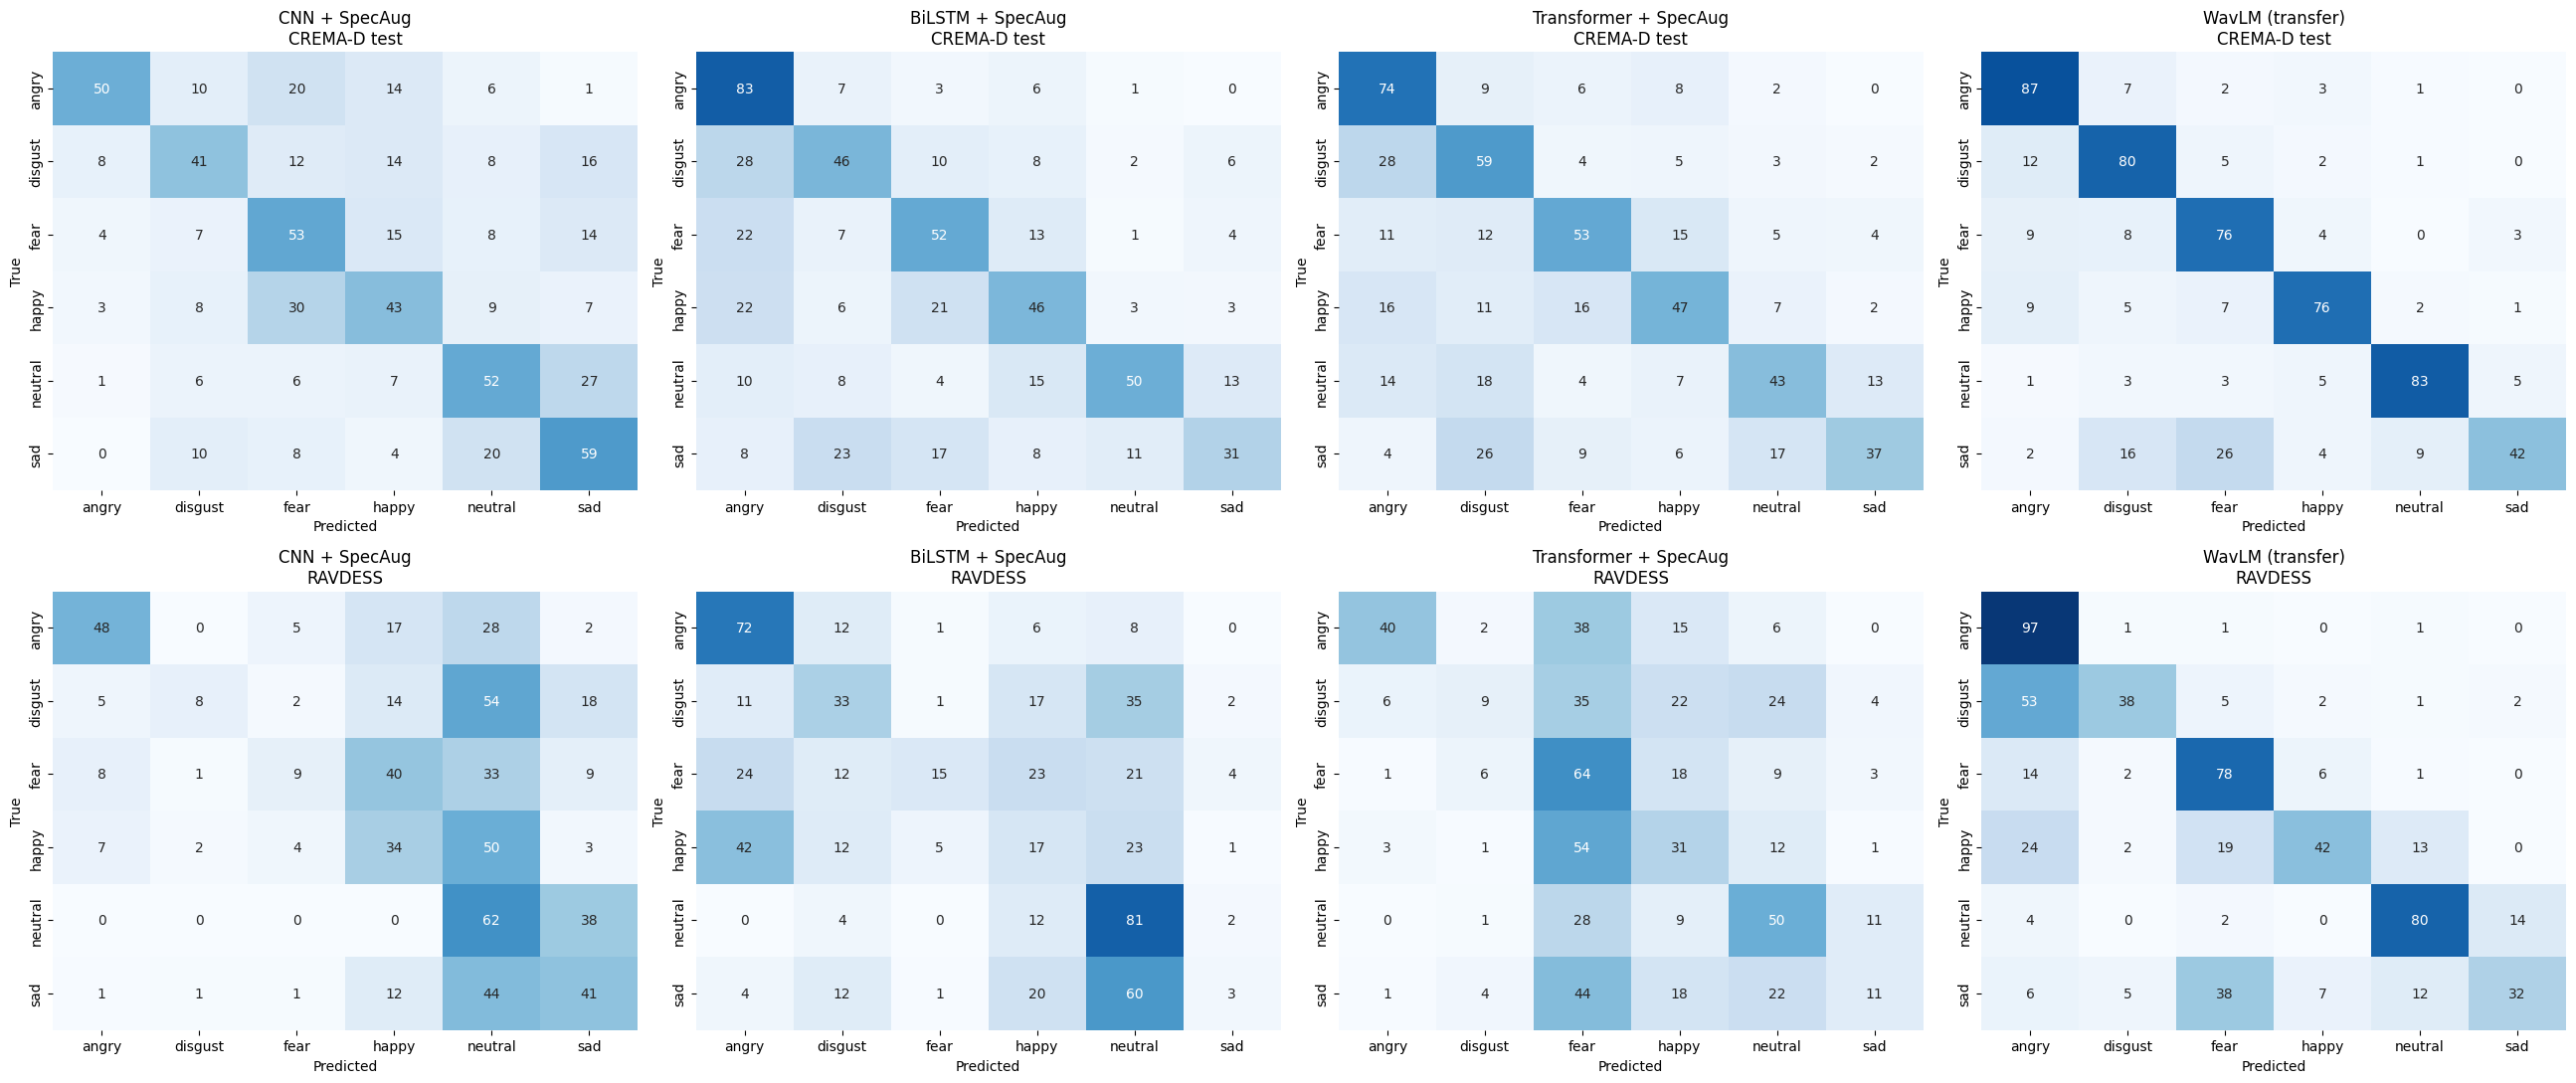

WavLM per-emotion results on CREMA-D test:

              precision    recall  f1-score   support

       angry      0.722     0.872     0.790       179
     disgust      0.676     0.804     0.735       179
        fear      0.642     0.760     0.696       179
       happy      0.810     0.760     0.784       179
     neutral      0.852     0.830     0.841       153
         sad      0.833     0.419     0.558       179

    accuracy                          0.739      1048
   macro avg      0.756     0.741     0.734      1048
weighted avg      0.753     0.739     0.731      1048



In [5]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

show = ["CNN + SpecAug", "BiLSTM + SpecAug", "Transformer + SpecAug", "WavLM (transfer)"]
fig, axes = plt.subplots(2, 4, figsize=(26, 11))
for row, split, title in [(0, "test", "CREMA-D test"), (1, "ravdess_test", "RAVDESS")]:
    for col, name in enumerate(show):
        cm = confusion_matrix(y[split], probs[name][split].argmax(1), labels=range(6), normalize="true") * 100
        sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False,
                    xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=axes[row, col])
        axes[row, col].set_title(f"{name}\n{title}")
        axes[row, col].set_xlabel("Predicted"); axes[row, col].set_ylabel("True")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_matrices.png", dpi=150); plt.show()

print("WavLM per-emotion results on CREMA-D test:\n")
print(classification_report(y["test"], probs["WavLM (transfer)"]["test"].argmax(1),
                            target_names=EMOTIONS, digits=3))

### Precision, recall and F1 per emotion
Computes precision, recall and F1 for every model and emotion on the test set and shows them as three heatmaps. The table is also saved as a CSV file.

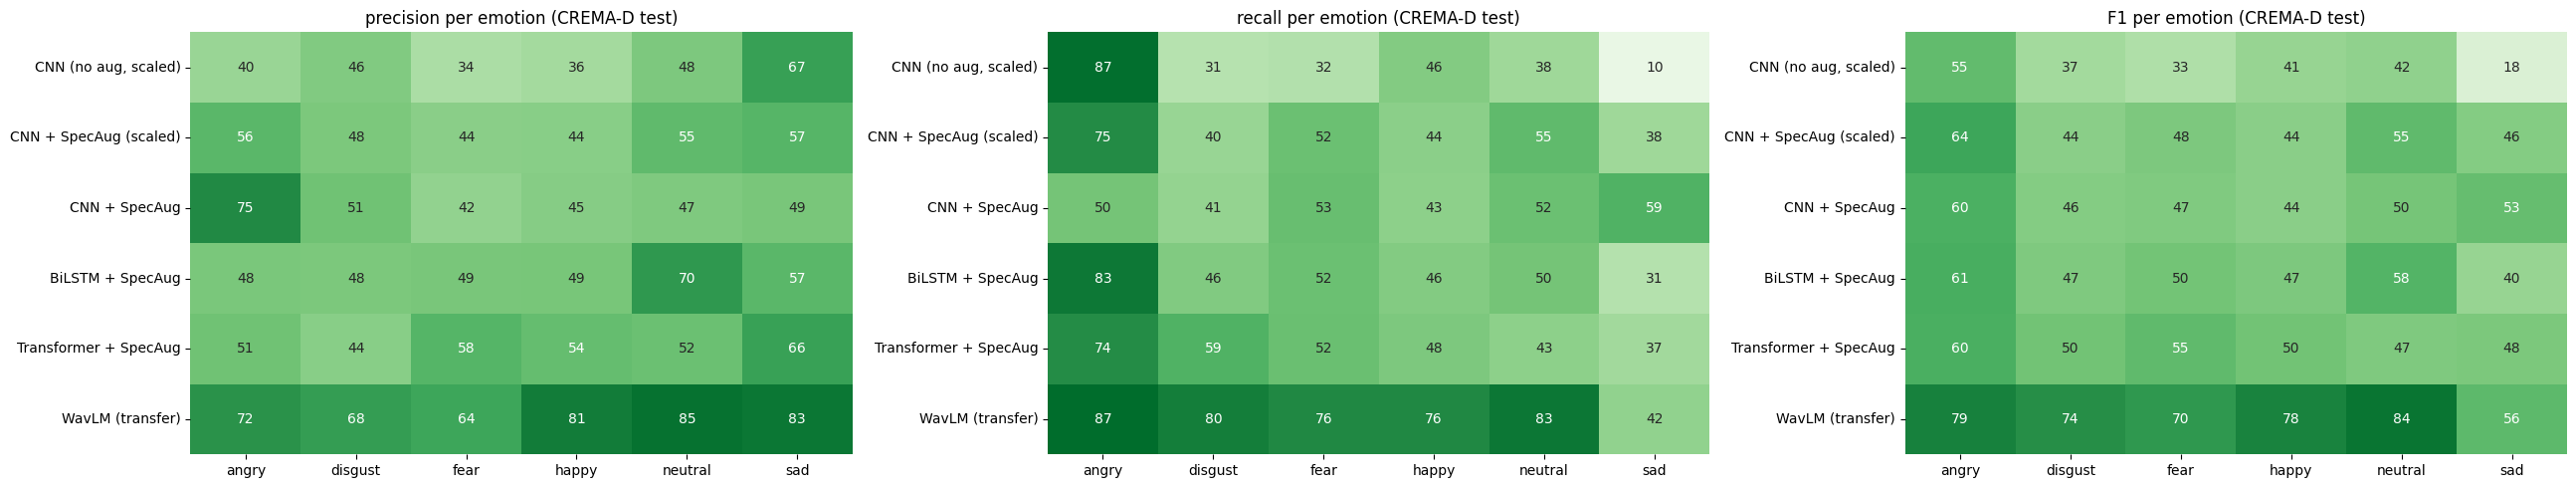

In [6]:
from sklearn.metrics import precision_recall_fscore_support

tables = {}
fig, axes = plt.subplots(1, 3, figsize=(26, 5))
for ax, (k, metric) in zip(axes, enumerate(["precision", "recall", "F1"])):
    M = []
    for name in probs:
        prf = precision_recall_fscore_support(y["test"], probs[name]["test"].argmax(1),
                                              labels=range(6), zero_division=0)
        M.append(prf[k])
    df = pd.DataFrame(np.array(M) * 100, index=list(probs), columns=EMOTIONS).round(1)
    tables[metric] = df
    sns.heatmap(df, annot=True, fmt=".0f", cmap="Greens", vmin=0, vmax=100, cbar=False, ax=ax)
    ax.set_title(f"{metric} per emotion (CREMA-D test)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/per_emotion_prf.png", dpi=150); plt.show()
pd.concat(tables, axis=1).to_csv(f"{LOG_DIR}/per_emotion_prf.csv")

### Model comparison chart
Plots test accuracy, test UAR and RAVDESS accuracy of all models as bars. The human listener score and random guessing are drawn as reference lines.

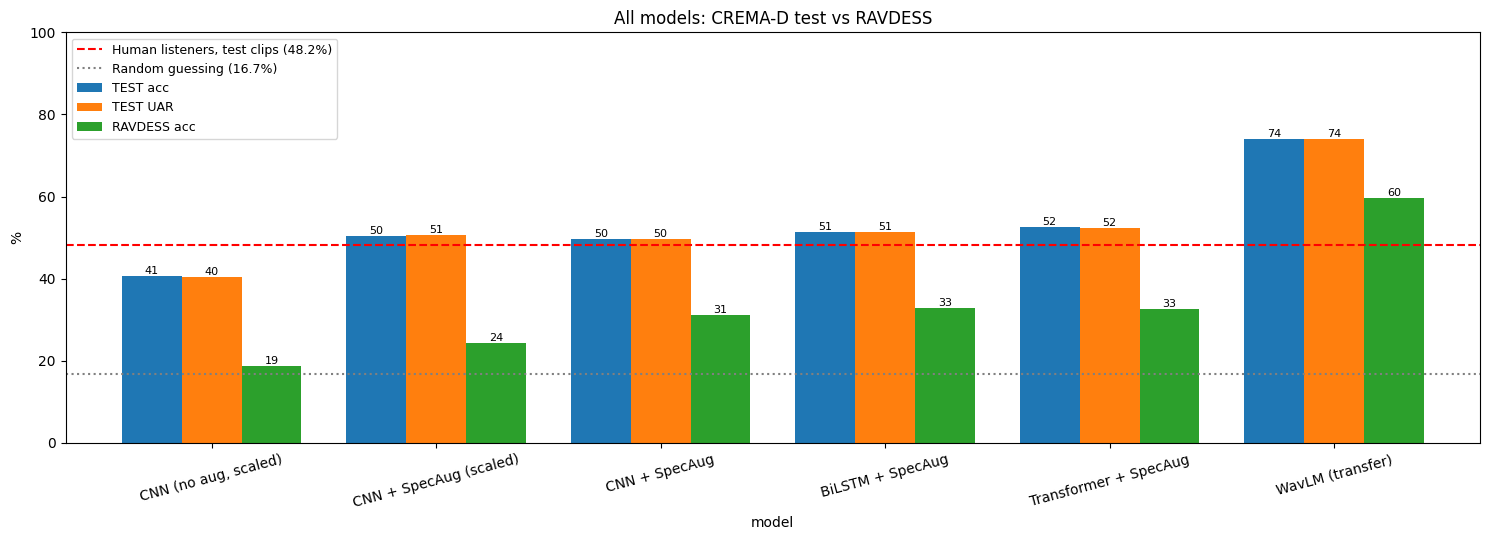

In [7]:
agree = data.loc[data["split"] == "test", "listeners_agree"].astype(str).str.lower().map({"true": 1, "false": 0}).values
human_acc = agree.mean() * 100

metrics = ["TEST acc", "TEST UAR", "RAVDESS acc"]
ax = results[metrics].plot(kind="bar", figsize=(15, 5.5), rot=15, width=0.8)
ax.axhline(human_acc, ls="--", color="red", label=f"Human listeners, test clips ({human_acc:.1f}%)")
ax.axhline(100 / 6, ls=":", color="grey", label="Random guessing (16.7%)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.set_title("All models: CREMA-D test vs RAVDESS")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/model_comparison.png", dpi=150); plt.show()

### Humans vs models per emotion
For each emotion on the test set, compares how often human listeners, the BiLSTM and WavLM match the intended label.

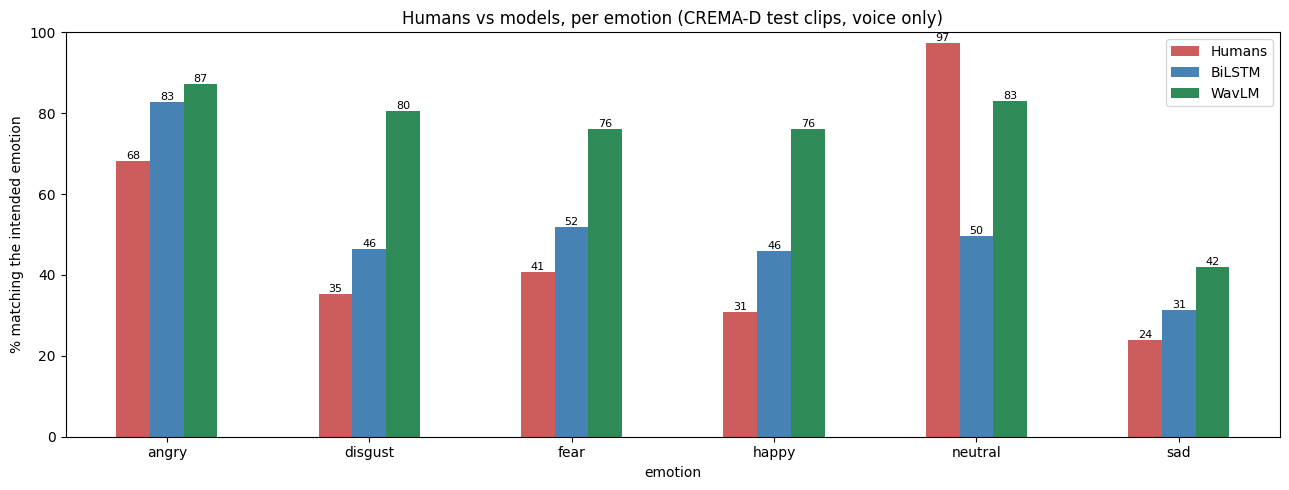

         Humans  BiLSTM  WavLM
emotion                       
angry      68.2    82.7   87.2
disgust    35.2    46.4   80.4
fear       40.8    52.0   76.0
happy      30.7    45.8   76.0
neutral    97.4    49.7   83.0
sad        24.0    31.3   41.9


In [8]:
test = data[data["split"] == "test"].reset_index(drop=True)
test["Humans"]      = agree
test["BiLSTM"]      = probs["BiLSTM + SpecAug"]["test"].argmax(1) == y["test"]
test["WavLM"]       = probs["WavLM (transfer)"]["test"].argmax(1) == y["test"]

per = test.groupby("emotion")[["Humans", "BiLSTM", "WavLM"]].mean().reindex(EMOTIONS) * 100
ax = per.plot(kind="bar", figsize=(13, 5), rot=0, color=["indianred", "steelblue", "seagreen"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
ax.set_ylabel("% matching the intended emotion"); ax.set_ylim(0, 100)
ax.set_title("Humans vs models, per emotion (CREMA-D test clips, voice only)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/humans_vs_models_per_emotion.png", dpi=150); plt.show()
print(per.round(1))

### Model accuracy on clear vs confusing clips
Splits the test clips into those where the listeners' vote matched the label and those where it did not, and measures every model on both groups. This checks whether the models struggle on the same clips as people.

Test clips: humans agreed on 505, disagreed on 543

                        humans AGREED with label  humans DISAGREED with label
model                                                                        
CNN (no aug, scaled)                        49.3                         32.4
CNN + SpecAug (scaled)                      58.2                         43.3
CNN + SpecAug                               56.6                         43.1
BiLSTM + SpecAug                            56.6                         46.4
Transformer + SpecAug                       59.4                         46.0
WavLM (transfer)                            84.0                         64.5


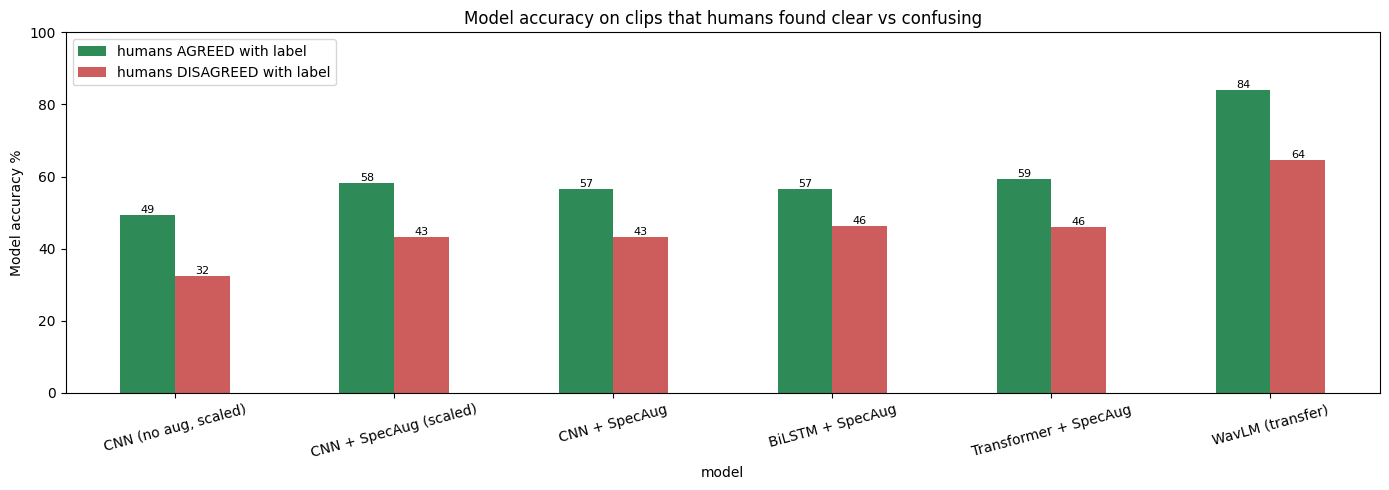

In [9]:
rows = []
for name in probs:
    correct = probs[name]["test"].argmax(1) == y["test"]
    rows.append({"model": name,
                 "humans AGREED with label":    correct[agree == 1].mean() * 100,
                 "humans DISAGREED with label": correct[agree == 0].mean() * 100})
hd = pd.DataFrame(rows).set_index("model").round(1)
print(f"Test clips: humans agreed on {int(agree.sum())}, disagreed on {int((agree == 0).sum())}\n")
print(hd.to_string())

ax = hd.plot(kind="bar", figsize=(14, 5), rot=15, color=["seagreen", "indianred"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
ax.set_ylabel("Model accuracy %"); ax.set_ylim(0, 100)
ax.set_title("Model accuracy on clips that humans found clear vs confusing")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/human_agreement_vs_model.png", dpi=150); plt.show()
hd.to_csv(f"{LOG_DIR}/human_agreement_vs_model.csv")

### Accuracy by gender and per speaker
Computes accuracy for female and male speakers on the test set and on RAVDESS for every model. The chart shows WavLM accuracy for each of the 13 test speakers.

                        test Female  test Male  RAVDESS Female  RAVDESS Male
model                                                                       
CNN (no aug, scaled)           40.4       40.7            19.1          18.2
CNN + SpecAug (scaled)         49.4       51.4            25.8          22.7
CNN + SpecAug                  52.7       47.0            32.0          30.5
BiLSTM + SpecAug               51.2       51.4            36.6          29.2
Transformer + SpecAug          51.0       53.7            26.3          39.0
WavLM (transfer)               73.3       74.3            59.3          59.8


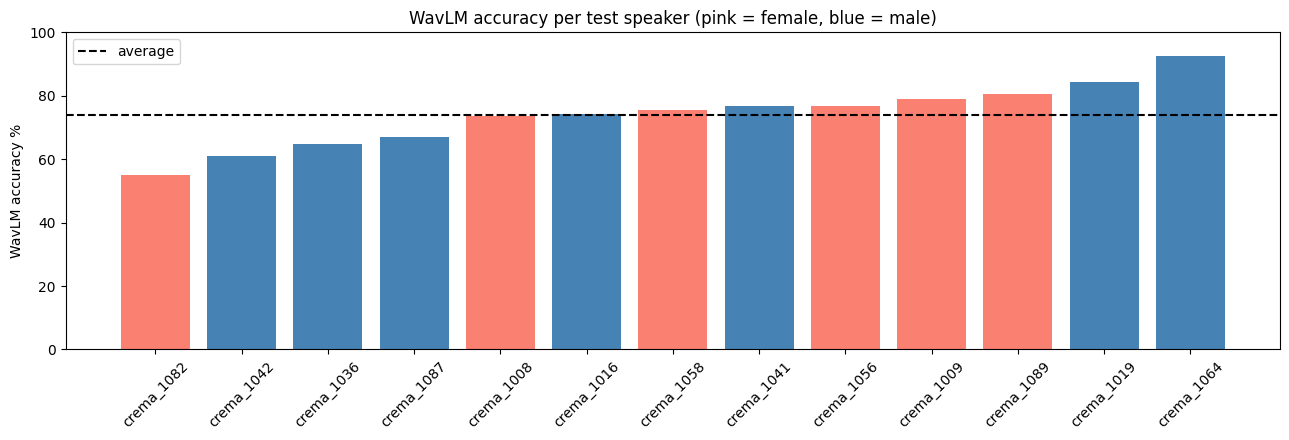

In [10]:
rav_df = data[data["split"] == "ravdess_test"].reset_index(drop=True)
rows = []
for name in probs:
    ct = probs[name]["test"].argmax(1) == y["test"]
    cr = probs[name]["ravdess_test"].argmax(1) == y["ravdess_test"]
    rows.append({"model": name,
                 "test Female": ct[test["gender"] == "Female"].mean() * 100,
                 "test Male":   ct[test["gender"] == "Male"].mean() * 100,
                 "RAVDESS Female": cr[rav_df["gender"] == "Female"].mean() * 100,
                 "RAVDESS Male":   cr[rav_df["gender"] == "Male"].mean() * 100})
gd = pd.DataFrame(rows).set_index("model").round(1)
print(gd.to_string()); gd.to_csv(f"{LOG_DIR}/accuracy_by_gender.csv")

spk = (test.assign(correct=test["WavLM"])
           .groupby(["speaker_id", "gender"])["correct"].mean().mul(100)
           .reset_index().sort_values("correct"))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(spk["speaker_id"], spk["correct"],
       color=spk["gender"].map({"Female": "salmon", "Male": "steelblue"}))
ax.axhline(spk["correct"].mean(), ls="--", color="black", label="average")
ax.set_ylabel("WavLM accuracy %"); ax.set_ylim(0, 100); ax.tick_params(axis="x", rotation=45)
ax.set_title("WavLM accuracy per test speaker (pink = female, blue = male)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/wavlm_per_speaker.png", dpi=150); plt.show()

### t-SNE: MFCC vs WavLM features
Computes MFCC statistics and fine-tuned WavLM embeddings for the test clips and plots both in 2D, coloured by emotion and by speaker. The nearest-neighbour check shows whether clips group by speaker or by emotion in each feature space.

MFCC (80 numbers, as in EDA): closest clip same SPEAKER 85% | same EMOTION 36%
WavLM (768 numbers, fine-tuned): closest clip same SPEAKER 38% | same EMOTION 71%


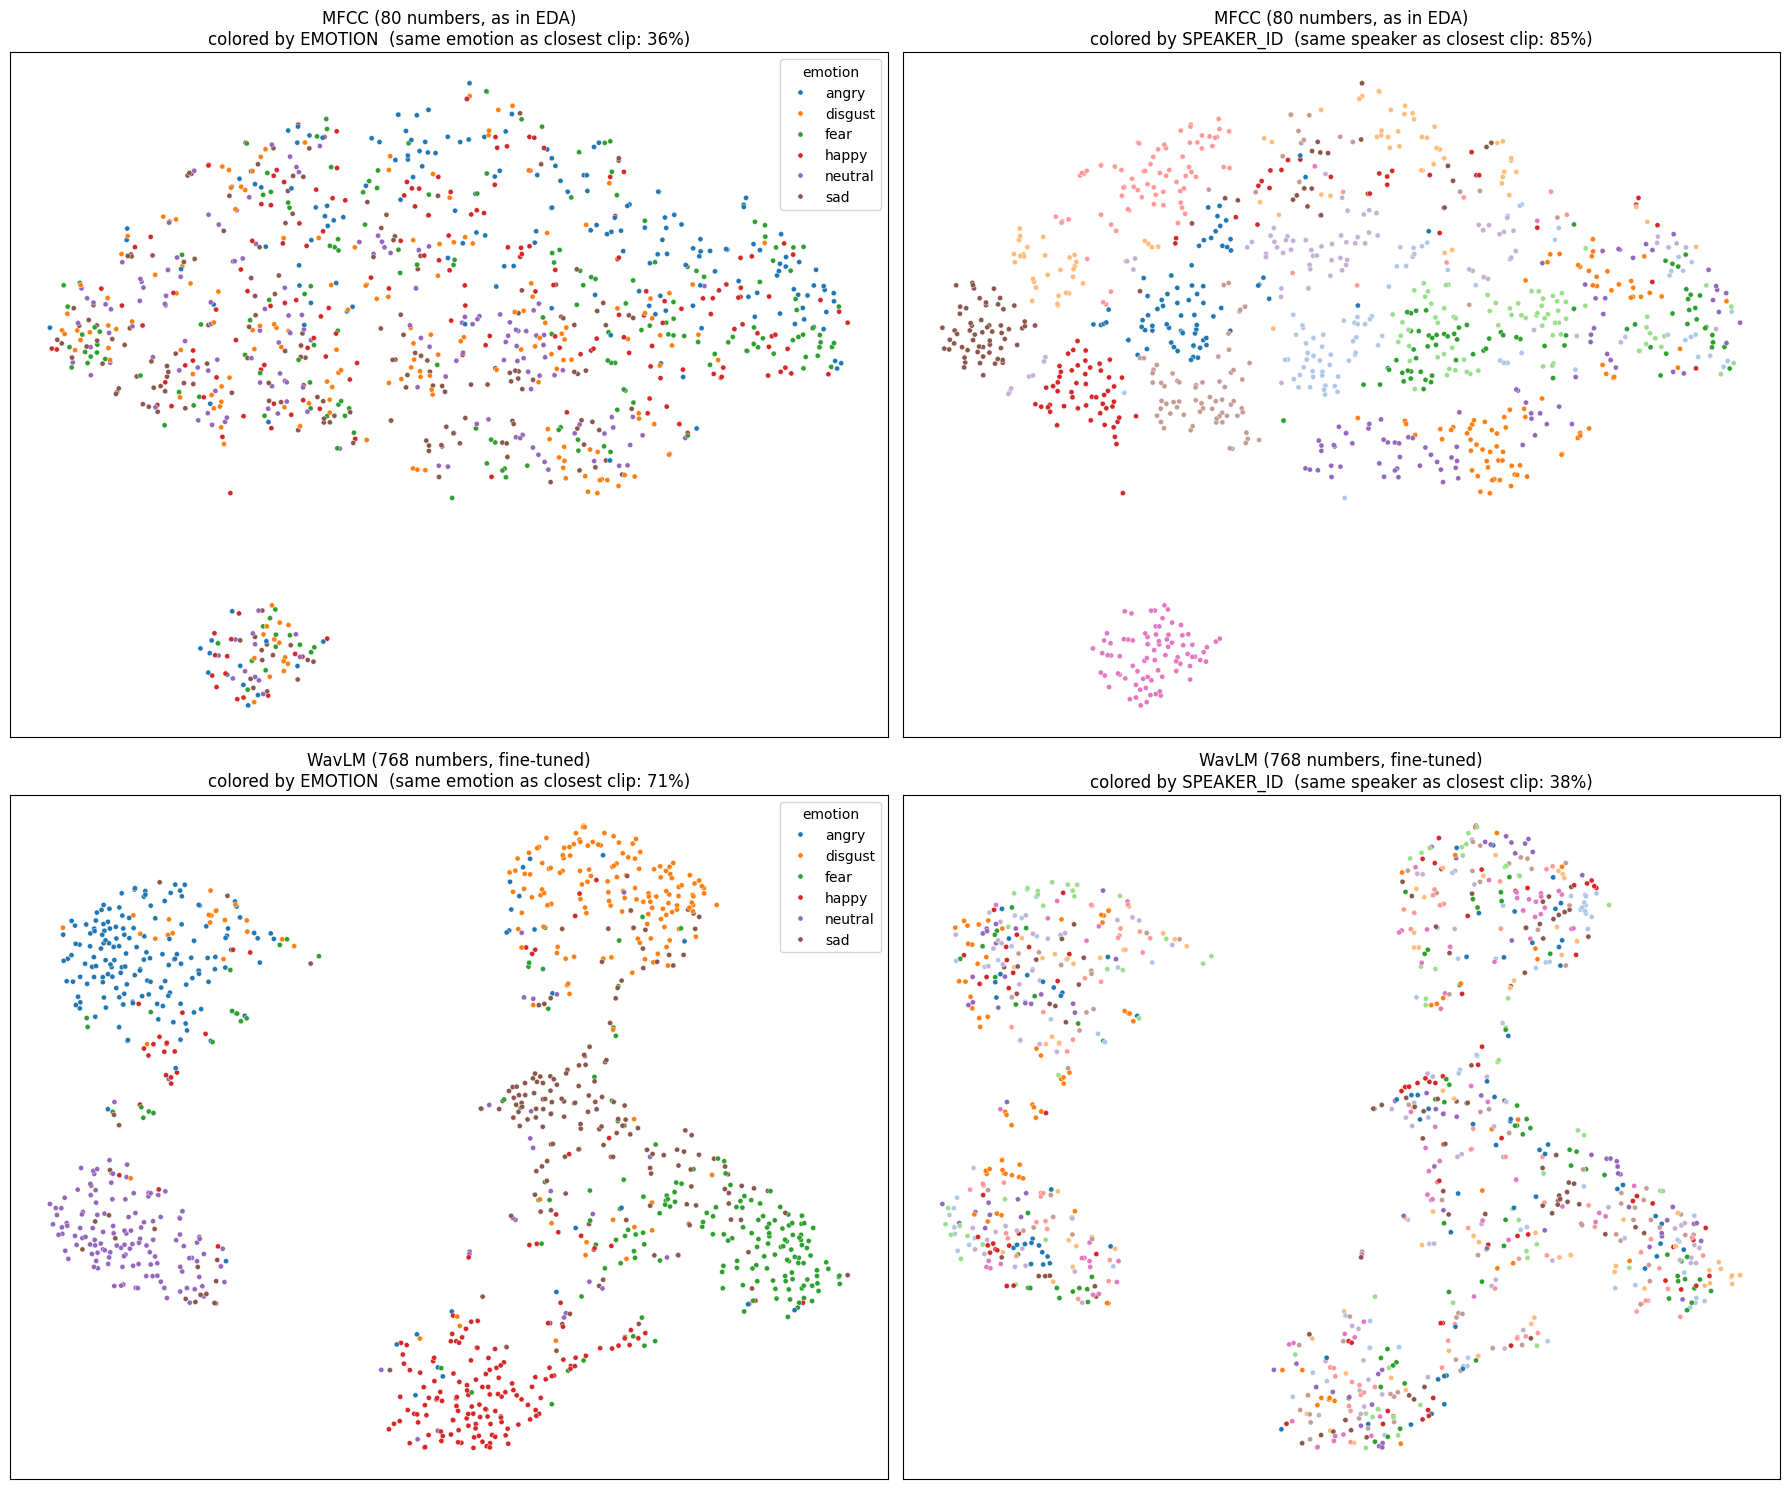

In [11]:
import librosa
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

test_idx = np.where(data["split"] == "test")[0]

def wavlm_embed(idx, bs=16):
    outs = []
    with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.float16):
        for i in range(0, len(idx), bs):
            xb = torch.from_numpy(W[idx[i:i + bs]].astype(np.float32)).to(device)
            hs = torch.stack(wavlm.wavlm(xb, output_hidden_states=True).hidden_states, dim=0)
            w = torch.softmax(wavlm.layer_weights, dim=0)
            outs.append((w[:, None, None, None] * hs).sum(0).mean(1).float().cpu().numpy())
    return np.concatenate(outs)

def mfcc_stats(y):
    nz = np.nonzero(y)[0]
    y = y[: nz[-1] + 1] if len(nz) else y
    m = librosa.feature.mfcc(y=y, sr=16000, n_mfcc=40, n_fft=400, hop_length=160)
    return np.concatenate([m.mean(1), m.std(1)])

feats = {"MFCC (80 numbers, as in EDA)": np.stack([mfcc_stats(W[i].astype(np.float32)) for i in test_idx]),
         "WavLM (768 numbers, fine-tuned)": wavlm_embed(test_idx)}

fig, axes = plt.subplots(2, 2, figsize=(18, 15))
for r, (fname, F) in enumerate(feats.items()):
    Fs = StandardScaler().fit_transform(F)
    emb = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(Fs)
    nn_idx = NearestNeighbors(n_neighbors=2).fit(Fs).kneighbors(Fs, return_distance=False)[:, 1]
    same_spk = (test["speaker_id"].values[nn_idx] == test["speaker_id"].values).mean() * 100
    same_emo = (test["emotion"].values[nn_idx] == test["emotion"].values).mean() * 100
    print(f"{fname}: closest clip same SPEAKER {same_spk:.0f}% | same EMOTION {same_emo:.0f}%")
    for c, (col, pal, order) in enumerate([("emotion", "tab10", EMOTIONS), ("speaker_id", "tab20", None)]):
        sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=test[col], hue_order=order, palette=pal,
                        s=14, ax=axes[r, c], legend=(c == 0))
        axes[r, c].set_title(f"{fname}\ncolored by {col.upper()}  (same {'emotion' if c == 0 else 'speaker'} "
                             f"as closest clip: {same_emo if c == 0 else same_spk:.0f}%)")
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/tsne_mfcc_vs_wavlm.png", dpi=150); plt.show()

### Training curves of all models
Reads the saved training histories of the BiLSTM, Transformer and WavLM and plots accuracy and validation loss on shared axes. The Keras logs count epochs from 0, so they are shifted by one.

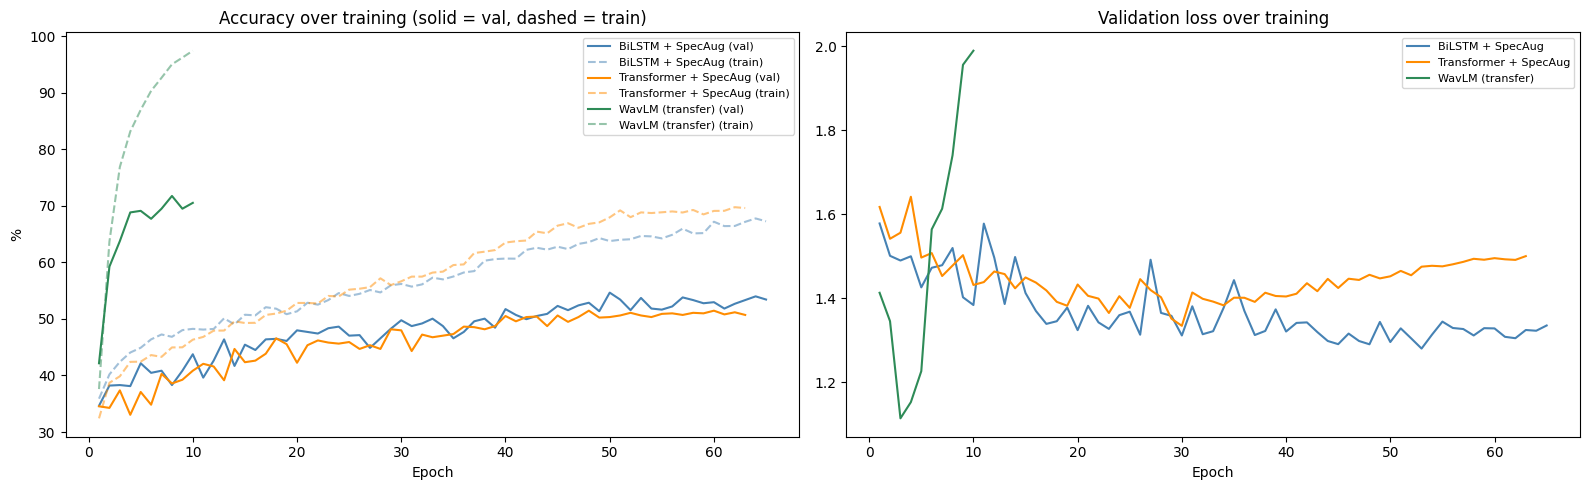

In [12]:
logs = {"BiLSTM + SpecAug":      ("bilstm_specaug_noscale_history.csv", 1),
        "Transformer + SpecAug": ("transformer_specaug_noscale_history.csv", 1),
        "WavLM (transfer)":      ("wavlm_noscale_history.csv", 0)}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for (name, (f, shift)), color in zip(logs.items(), ["steelblue", "darkorange", "seagreen"]):
    h = pd.read_csv(f"{LOG_DIR}/{f}")
    ep = h["epoch"] + shift
    axes[0].plot(ep, h["val_accuracy"] * 100, color=color, label=f"{name} (val)")
    axes[0].plot(ep, h["accuracy"] * 100, color=color, ls="--", alpha=0.5, label=f"{name} (train)")
    axes[1].plot(ep, h["val_loss"], color=color, label=name)
axes[0].set_title("Accuracy over training (solid = val, dashed = train)"); axes[0].set_ylabel("%")
axes[1].set_title("Validation loss over training")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/training_curves_all.png", dpi=150); plt.show()